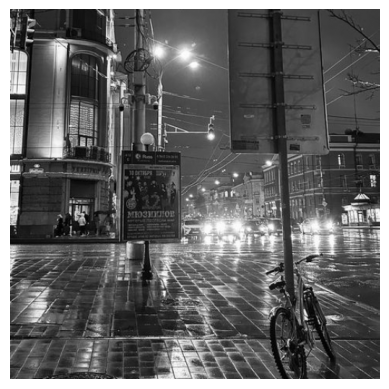

Размер: (512, 512)


In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('sar_1_gray.jpg', cv2.IMREAD_GRAYSCALE)
h, w = img.shape
s = min(h, w)
img = cv2.resize(img[(h-s)//2:(h+s)//2, (w-s)//2:(w+s)//2], (512, 512))
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()
print('Размер:', img.shape)

In [10]:
# прямое и обратное преобразование Хаара

def haar(image, levels):
    c = image.astype(np.float32)
    for l in range(levels):
        n = c.shape[0] >> l
        b = c[:n, :n]
        b = np.hstack(((b[:, 0::2] + b[:, 1::2]) / 2,
                       (b[:, 0::2] - b[:, 1::2]) / 2))
        c[:n, :n] = np.vstack(((b[0::2] + b[1::2]) / 2,
                               (b[0::2] - b[1::2]) / 2))
    return c

def ihaar(coef, levels):
    c = coef.copy()
    for l in range(levels - 1, -1, -1):
        n = c.shape[0] >> l
        k = n // 2
        b = c[:n, :n]
        t = np.empty_like(b)
        t[0::2], t[1::2] = b[:k] + b[k:], b[:k] - b[k:]
        c[:n, :n][:, 0::2], c[:n, :n][:, 1::2] = t[:, :k] + t[:, k:], t[:, :k] - t[:, k:]
    return c

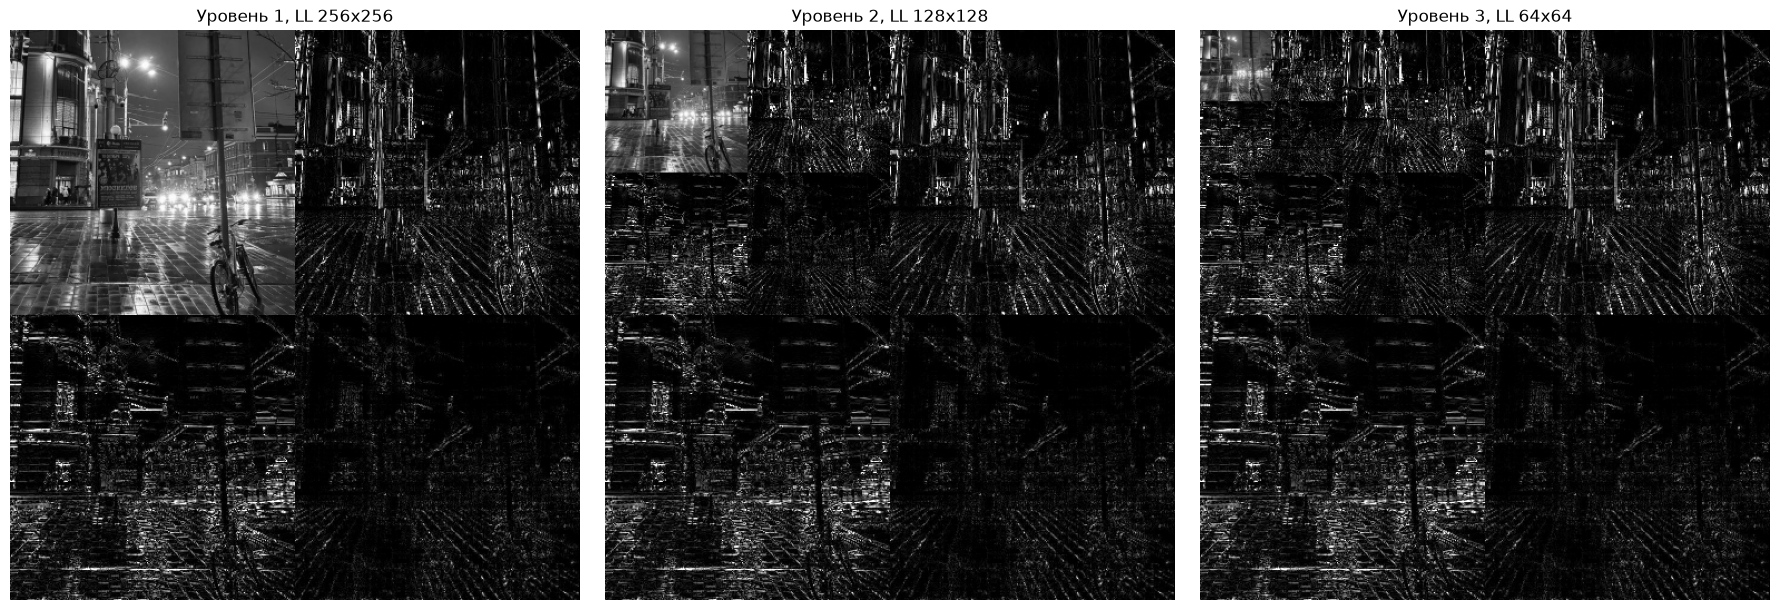

In [11]:
# визуализация 3 уровней

plt.figure(figsize=(18, 6))
for l in range(1, 4):
    c = haar(img, l)
    vis = np.clip(np.abs(c) * 5, 0, 255)
    n = 512 >> l
    vis[:n, :n] = c[:n, :n]
    plt.subplot(1, 3, l)
    plt.imshow(vis, cmap='gray')
    plt.title('Уровень ' + str(l) + ', LL ' + str(n) + 'x' + str(n))
    plt.axis('off')
plt.tight_layout(); plt.show()

Ошибка восстановления: 0.0
Обнулено: 85.4 %   MSE: 96.03


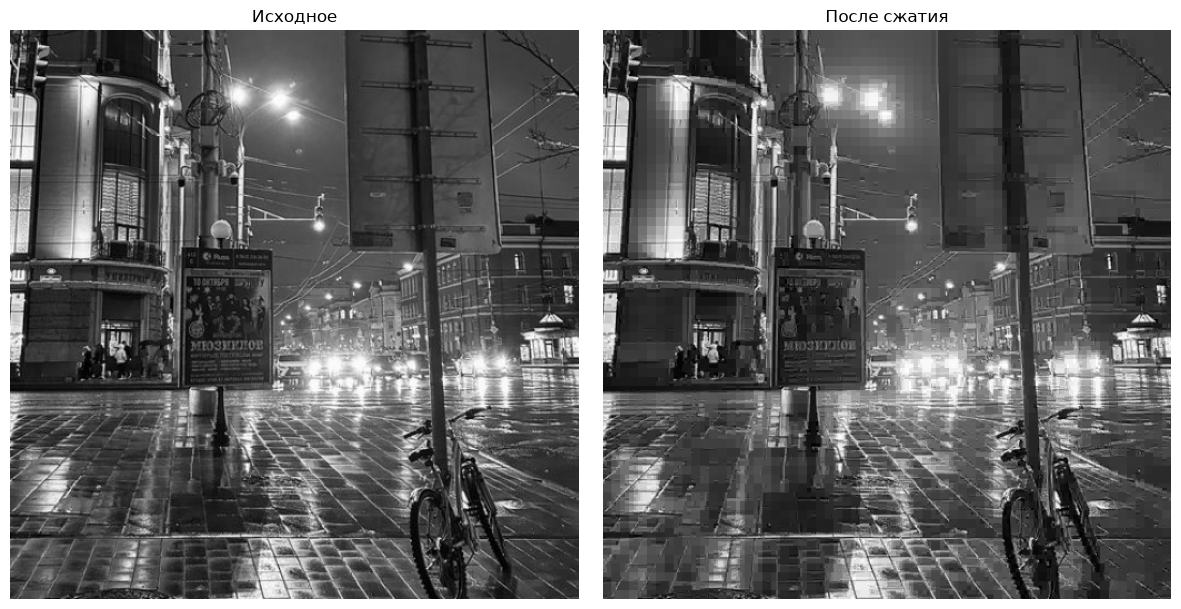

In [12]:
# проверка восстановления и сжатие

coef = haar(img, 3)
print('Ошибка восстановления:', np.abs(ihaar(coef, 3) - img).max())

T = 10
c = coef.copy()
c[np.abs(c) < T] = 0
c[:64, :64] = coef[:64, :64]

res = np.clip(ihaar(c, 3), 0, 255)
print('Обнулено:', round(np.mean(c == 0) * 100, 1), '%   MSE:', round(np.mean((res - img) ** 2), 2))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1); plt.imshow(img, cmap='gray'); plt.title('Исходное');     plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(res, cmap='gray'); plt.title('После сжатия'); plt.axis('off')
plt.tight_layout(); plt.show()